In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

In [3]:
global M
global OMEGA
global HBAR
global G
global G_M


M = 1e-18      
OMEGA1 = 2*np.pi*1e5   
OMEGA2 = np.pi*1e5/4   
OMEGA = OMEGA1
HBAR = 1.054571817e-34 

G = 2*np.pi*2.54e3
G_M = 2*np.pi*130

In [ ]:
def cov_fe(V_X0, V_P0, V_XP0, t):

    '''
    Calculates the variance of x, p, and covariance of x with p after given time t in free evolution.

    Inputs
    =========================================
    V_X0: Intial variance of x
    V_P0: Intial variance of p
    V_XP0: Intial covariance of x an p
    t: Time spent in free evolution

    returns
    =========================================
    Final variance of x, p, and covariance of x with p
    '''

    V_x = V_X0 + t**3*(G_M*HBAR**2/(3*M**2)) + t*(2*V_XP0/M) + t**2*(V_P0/M**2)
    V_p = G_M*HBAR**2*t + V_P0
    V_xp = V_XP0 + t**2*(G_M*HBAR**2/(2*M)) + t*(V_P0/M)

    return V_x, V_p, V_xp


def cov_ho(V_X0, V_P0, V_XP0, OMEGA, t):
    '''
    Calculates the variance of x, p, and covariance of x with p after given time t in a harmonic potential with frequency OMEGA.

    Inputs
    =========================================
    V_X0: Intial variance of x
    V_P0: Intial variance of p
    V_XP0: Intial covariance of x an p
    OMEGA: Oscillation frequency
    t: Time spent in harmonic potential

    returns
    =========================================
    Final variance of x, p, and covariance of x with p
    '''

    V_x = -(G+G_M)*HBAR**2*t/(2*M**2*OMEGA**2) + V_P0*np.sin(OMEGA*t)**2/(M**2*OMEGA**2) + V_X0*np.cos(OMEGA*t)**2 + np.sin(2*OMEGA*t)*V_XP0/(M*OMEGA) + (G+G_M)*HBAR**2*np.sin(2*OMEGA*t)/(4*M**2*OMEGA**3)
    V_p = np.cos(OMEGA*t)**2*V_P0 + M**2*OMEGA**2*np.sin(OMEGA*t)**2*V_X0 - M*OMEGA*V_XP0*np.sin(2*OMEGA*t) + np.sin(2*OMEGA*t)*(G+G_M)*HBAR**2/(4*OMEGA) + (G+G_M)*HBAR**2*t/2
    V_xp = V_XP0*np.cos(2*OMEGA*t) - M*OMEGA*np.sin(2*OMEGA*t)*V_X0/2 + V_P0*np.sin(2*OMEGA*t)/(2*OMEGA*M) + (G+G_M)*HBAR**2*np.sin(OMEGA*t)**2/(2*M*OMEGA**2)

    return V_x, V_p, V_xp


def cm(V_x, V_p, V_xp):

    '''
    Constructs the dimensionless covariance matrix in units x0, p0, and x0p0 respectively.

    Inputs
    =========================================
    V_X: Intial variance of x
    V_P: Intial variance of p
    V_XP: Intial covariance of x an p

    returns
    =========================================
    Covariance matrix
    '''

    x0 = np.sqrt(HBAR/(2*M*OMEGA))
    p0 = np.sqrt((M*OMEGA*HBAR/2))
    cov_matrix = np.array([[V_x/x0**2, V_xp/(x0*p0)],[V_xp/(x0*p0), V_p/p0**2]])
    
    return cov_matrix

def switching(V_X0, V_P0, V_XP0, t_ho, t_fe, rep):
    '''
    Switches between a harmonic potential with frequencies OMEGA1 and free evolution. After all repetitions are done, oscllator is trapped in harmonic potential.

    Inputs
    =========================================
    V_X0: Intial variance of x
    V_P0: Intial variance of p
    V_XP0: Intial covariance of x an p
    t_ho1: Time spent in harmonic potential 1 
    t_fe: Time spent in free evolution
    rep: Repetitions of potential switching

    returns
    =========================================
    plot of final ellipse
    Final variance of x, p, and covariance of x with p
    
    '''

    fig, ax = plt.subplots()

    def plot_ellipse(V_x, V_p, V_xp, col, label):
        minor, major, angle = get_ellipse(V_x, V_p, V_xp)
        ellipse = Ellipse((0, 0), 2*major, 2*minor, angle=angle, fill=False, linewidth=2, color=col, label=label)
        ax.add_patch(ellipse)

        limit = 1.2*major
        ax.set_xlim(-limit, limit)
        ax.set_ylim(-limit, limit)
        ax.set_aspect('equal', adjustable='box')

        ax.set_xlabel('x (x0)')
        ax.set_ylabel('p (p0)')
        ax.grid(True)
        plt.legend()

    V_x = V_X0
    V_p = V_P0
    V_xp = V_XP0

    for i in range(rep):
        V_x, V_p, V_xp = cov_ho(V_x, V_p, V_xp, OMEGA1, t_ho)
        plot_ellipse(V_x, V_p, V_xp, 'red', f'{i} HO')
        V_x, V_p, V_xp = cov_fe(V_x, V_p, V_xp, t_fe)
        plot_ellipse(V_x, V_p, V_xp, 'k', f'{i} FE')

    V_x, V_p, V_xp = cov_ho(V_x, V_p, V_xp, OMEGA1, t_ho)
    plot_ellipse(V_x, V_p, V_xp, 'blue', f'HO')

    return V_x, V_p, V_xp


def switching_ho(V_X0: float, V_P0: float, V_XP0: float, t_ho1: float, t_ho2: float, rep: int):
    '''
    Switches between two harmonic potentials with frequencies OMEGA1, OMEGA2. After all repetitions are done, oscllator is trapped in harmonic potential 1.

    Inputs
    =========================================
    V_X0: Intial variance of x
    V_P0: Intial variance of p
    V_XP0: Intial covariance of x an p
    t_ho1: Time spent in harmonic potential 1 
    t_ho2: Time spent in harmonic potential 2
    rep: Repetitions of potential switching

    returns
    =========================================
    plot of final ellipse
    Final variance of x, p, and covariance of x with p
    
    '''

    fig, ax = plt.subplots()

    def plot_ellipse(V_x, V_p, V_xp, col, label):
        minor, major, angle = get_ellipse(V_x, V_p, V_xp)
        ellipse = Ellipse((0, 0), 2*major, 2*minor, angle=angle, fill=False, linewidth=2, color=col, label=label)
        ax.add_patch(ellipse)

        limit = 1.2*major
        ax.set_xlim(-limit, limit)
        ax.set_ylim(-limit, limit)
        ax.set_aspect('equal', adjustable='box')

        ax.set_xlabel('x (x0)')
        ax.set_ylabel('p (p0)')
        ax.grid(True)
        plt.legend()

    V_x = V_X0
    V_p = V_P0
    V_xp = V_XP0

    for i in range(rep):
        V_x, V_p, V_xp = cov_ho(V_x, V_p, V_xp, OMEGA1, t_ho1)
        plot_ellipse(V_x, V_p, V_xp, 'red', f'{i} HO1')
        V_x, V_p, V_xp = cov_ho(V_x, V_p, V_xp, OMEGA2, t_ho2)
        plot_ellipse(V_x, V_p, V_xp, 'k', f'{i} HO2')

    V_x, V_p, V_xp = cov_ho(V_x, V_p, V_xp, OMEGA1, t_ho1)
    plot_ellipse(V_x, V_p, V_xp, 'blue', f'HO1')

    return V_x, V_p, V_xp


def get_ellipse(V_x, V_p, V_xp):
    '''
    Calculates the attributes of an ellipse given the covariance matrix elements.

    Inputs
    =========================================
    V_X: variance of x
    V_P: variance of p
    V_XP: covariance of x an p

    returns
    =========================================
    Minor and major axis of ellipse, and angle of major axis with x axis.
    
    '''
    
    cov_matrix = cm(V_x, V_p, V_xp)

    eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    major, minor = np.sqrt(eigenvalues)
    angle = np.degrees(np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0]))

    return minor, major, angle


   


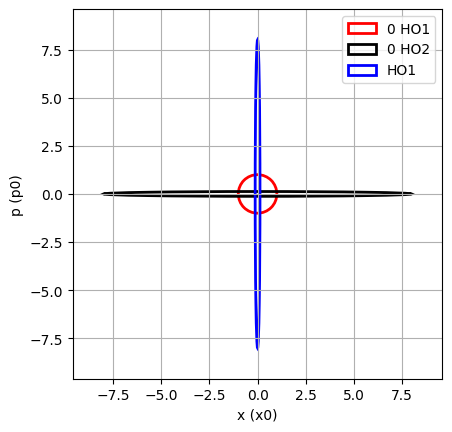

In [8]:
P_0 = np.sqrt(M*HBAR*OMEGA/2)/2*0
X_0 = 0.0
X2_0 = HBAR/(2*M*OMEGA)
P2_0 = M*HBAR*OMEGA/2
XPPX_0 = 0.0
V_X0 = X2_0 - X_0**2
V_P0 = P2_0 - P_0**2
V_XP0 = 1/2*(XPPX_0) - X_0*P_0

t_ho1 = 1*np.pi/(2*OMEGA1)
t_ho2 = 1*np.pi/(2*OMEGA2)

V_x, V_p, V_xp = switching_ho(V_X0, V_P0, V_XP0, t_ho1, t_ho2, 1)

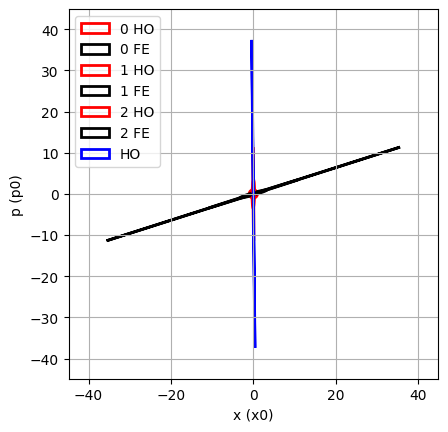

In [11]:
t_ho = 1.19*np.pi/(2*OMEGA)
t_fe = 2*np.pi/(2*OMEGA)

V_x, V_p, V_xp = switching(V_X0, V_P0, V_XP0, t_ho, t_fe, 3)